![DesignTask Image[4].jpg](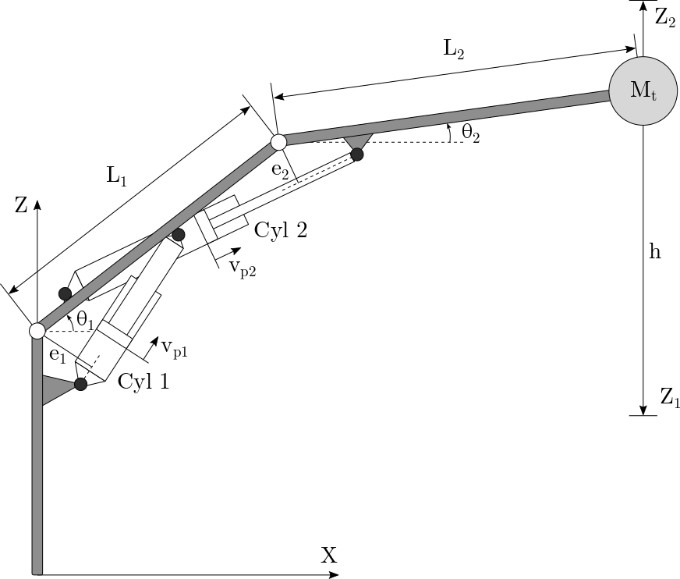)

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

## Initial conditions

In [ ]:
g = 9.81 # m/s2
cv = 1.3e-9 # rev
kp = 5.4e-2
kv = 6.5e-5
ke = 0.3
viscoEff = 0.03 # Ns/m2 η
Plow = 1.0e6 # Pa

In [ ]:
Mtmax = 1100 #kg
qrwc = 0.95
Mt = 900 #kg
L1 = 1.9 #m
L2 = 3.5 #m
vp0 = 0.1 #m/s
t0 = 12 #s
Psmax = 250 #bar  1 bar = 1e5Pa
effC = 0.96

## Drive cycle

In [ ]:
v_p01 = np.array([0, 0.13, 0.26, 0.4, 0.386, 0.372, 0.358, 0.344, 0.33, 0.316, 0.302, 0.288, 0.274, 0.26, 0.246, 0.232, 0.218, 0.204, 0.19, 0.176, 0.162, 0.148, 0.134, 0.12, 0.106, 0.092, 0.078, 0.064, 0.05, 0.036, 0.022, 0.008, 0, 0, 0, 0, 0, 0, 0, 0, 0])
v_p02 = np.array([0, -0.1, -0.2, -0.2, -0.2, -0.2, -0.2, -0.2, -0.2, -0.2, -0.16, -0.12, -0.08, -0.04, 0, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24, 0.28, 0.32, 0.36, 0.4, 0.44, 0.48, 0.52, 0.56, 0.6, 0.64, 0.68, 0.72, 0.76, 0.8, 0.5333333333, 0.26666667, 0, 0, 0, 0])
e_1 = np.array([0.322, 0.3192, 0.3164, 0.3136, 0.3108, 0.308, 0.3052, 0.3024, 0.2996, 0.2968, 0.294, 0.2912, 0.2884, 0.2856, 0.2828, 0.28, 0.278, 0.276, 0.274, 0.273, 0.272, 0.271, 0.27, 0.269, 0.268, 0.2674, 0.2668, 0.2662, 0.2656, 0.265, 0.265, 0.265, 0.267, 0.267, 0.267, 0.267, 0.267, 0.267, 0.267, 0.267, 0.267])
e_2 = np.array([0.535, 0.5365, 0.538, 0.539125, 0.54025, 0.541, 0.54175, 0.5425, 0.54325, 0.543625, 0.544, 0.544, 0.544, 0.5439, 0.5437, 0.5435, 0.543, 0.542, 0.541, 0.54, 0.53875, 0.537, 0.535, 0.533, 0.531, 0.529, 0.526, 0.523, 0.52, 0.516, 0.512, 0.506, 0.5, 0.492, 0.492, 0.492, 0.492, 0.492, 0.492, 0.492, 0.492])
th_1 = np.array([0.55, 0.56, 0.57, 0.585, 0.6, 0.62, 0.65, 0.67, 0.7, 0.73, 0.76, 0.78, 0.8, 0.815, 0.835, 0.85, 0.87, 0.885, 0.9, 0.915, 0.93, 0.945, 0.96, 0.97, 0.98, 0.99, 0.995, 1.005, 1.01, 1.015, 1.02, 1.02, 1.02, 1.012, 1, 1, 1, 1, 1, 1, 1])
th_2 = np.array([-0.62, -0.62, -0.61, -0.6, -0.585, -0.57, -0.55, -0.53, -0.51, -0.495, -0.48, -0.46, -0.44, -0.42, -0.4, -0.38, -0.36, -0.345, -0.32, -0.3, -0.28, -0.26, -0.24, -0.22, -0.2, -0.175, -0.15, -0.12, -0.09, -0.06, -0.03, 0, 0.04, 0.08, 0.12, 0.12, 0.12, 0.12, 0.12, 0.12, 0.12])
v_p01 = np.concatenate((v_p01, -np.flip(v_p01)))
v_p02 = np.concatenate((v_p02, -np.flip(v_p02)))
e_1 = np.concatenate((e_1, np.flip(e_1)))
e_2 = np.concatenate((e_2, np.flip(e_2)))
th_1 = np.concatenate((th_1, np.flip(th_1)))
th_2 = np.concatenate((th_2, np.flip(th_2)))
t = np.linspace(0, t0, len(th_1)) # Create a time array from 0 to t0 with the same length as th_1

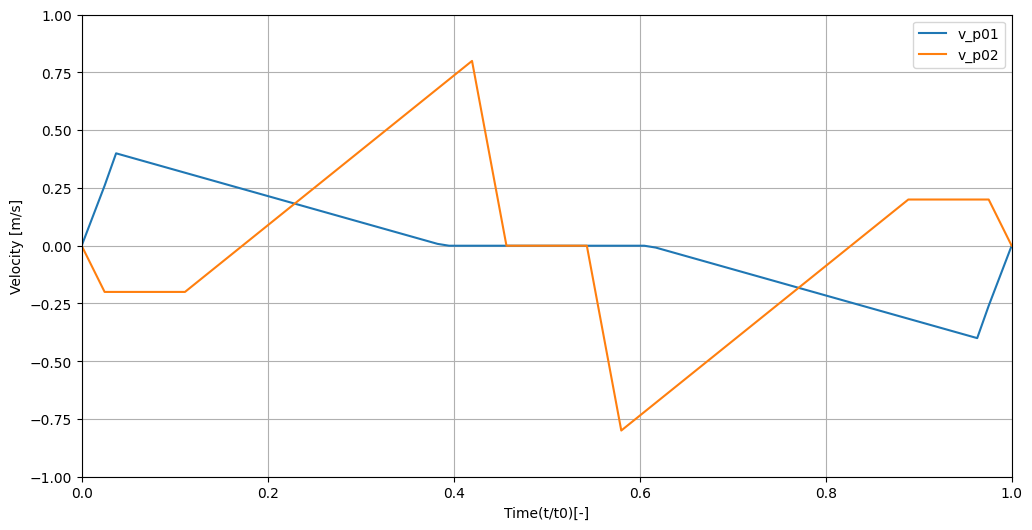

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t / t0, v_p01, label='v_p01')
plt.plot(t / t0, v_p02, label='v_p02')
plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Velocity [m/s]')
plt.grid(True)
plt.legend()
plt.ylim(-1.0,1.0)
plt.xlim(0.0,1.0)
plt.show()

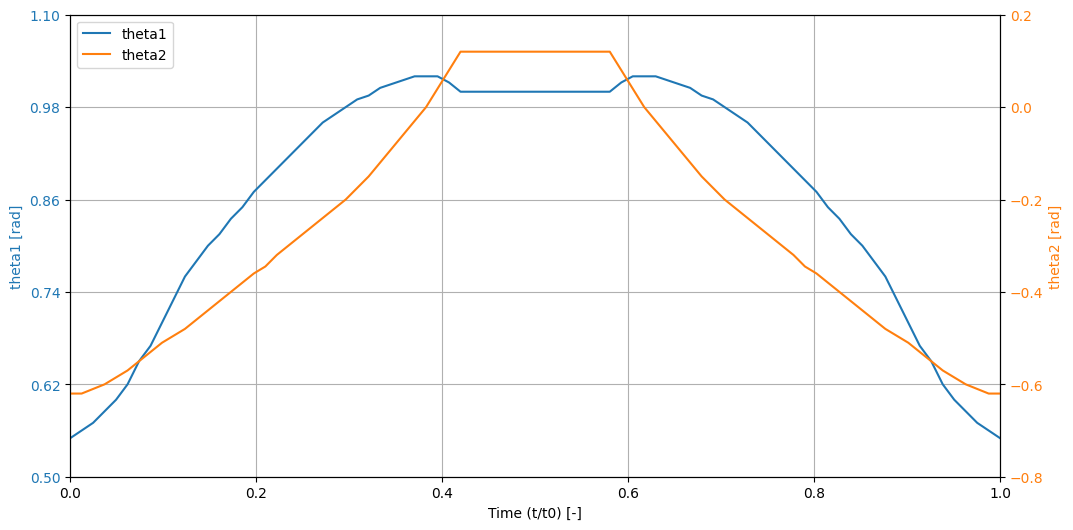

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Time (t/t0) [-]')
ax1.set_ylabel('theta1 [rad]', color=color)
line1 = ax1.plot(t / t0, th_1, color=color, label='theta1')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True)

ax1.set_ylim(0.5, 1.1)
ax1.set_yticks(np.arange(0.5, 1.11, 0.12))

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('theta2 [rad]', color=color)
line2 = ax2.plot(t / t0, th_2, color=color, label='theta2')
ax2.tick_params(axis='y', labelcolor=color)

ax2.set_ylim(-0.8, 0.2)
ax2.set_yticks(np.arange(-0.8, 0.21, 0.2))

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')
plt.xlim(0.0, 1.0)
#plt.title('Theta1 and Theta2 over the Drive Cycle')
plt.show()

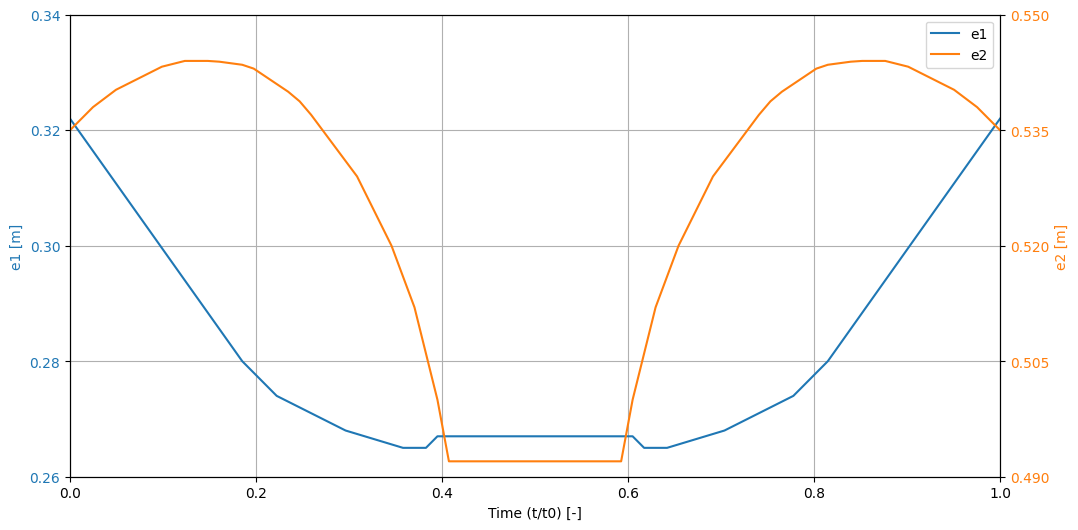

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Left y-axis: e1
color = 'tab:blue'
ax1.set_xlabel('Time (t/t0) [-]')
ax1.set_ylabel('e1 [m]', color=color)
line1 = ax1.plot(t / t0, e_1, color=color, label='e1')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True)

# Set limits and ticks for left y-axis
ax1.set_ylim(0.26, 0.34)
ax1.set_yticks(np.arange(0.26, 0.341, 0.02))

# Right y-axis: e2
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('e2 [m]', color=color)
line2 = ax2.plot(t / t0, e_2, color=color, label='e2')
ax2.tick_params(axis='y', labelcolor=color)

# Set limits and ticks for right y-axis
ax2.set_ylim(0.490, 0.550)
ax2.set_yticks(np.arange(0.490, 0.551, 0.015))

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.xlim(0.0, 1.0)
#plt.title('e1 and e2 over the Drive Cycle')
plt.show()

###Worst-case scenario

In [ ]:
#Base height [m]
L_0 = 3;
#worst case senerio for cylinder 1
th_1_wc_cyl1 = 1.2
th_2_wc_cyl1 = 0.0
e_1_wc_cyl1 = 0.14
e_2_wc_cyl1 = 0.57

#worst case senerio for cylinder 2
th_1_wc_cyl2 = 0.35
th_2_wc_cyl2 = 0.0
e_1_wc_cyl2 = 0.48
e_2_wc_cyl2 = 0.17

## 1 Analyse the crane’s movement during the drive cycle

In [ ]:
z_cranetip = L1 * np.sin(th_1) + L2 * np.sin(th_2) + L_0
x_cranetip = L1 * np.cos(th_1) + L2 * np.cos(th_2)

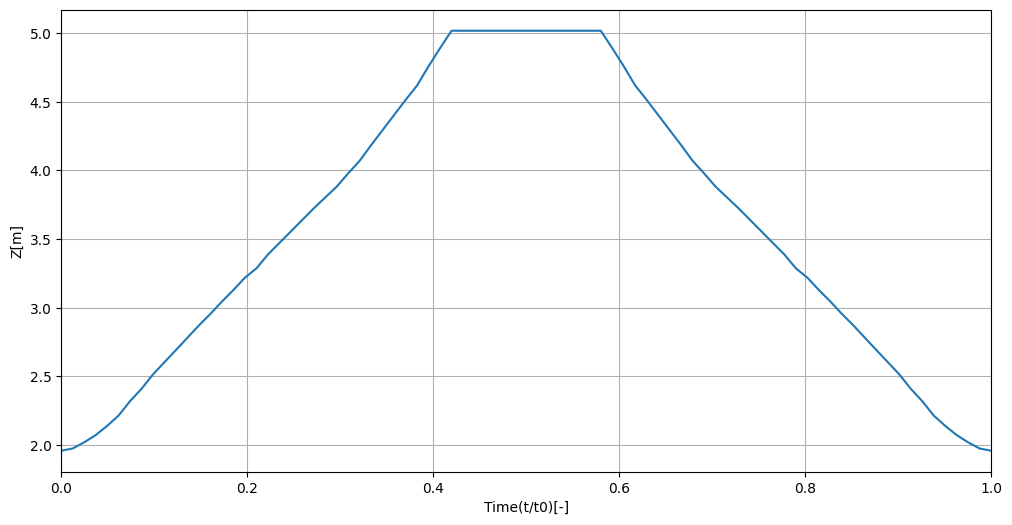

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t/ t0, z_cranetip)
plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Z[m]')
plt.grid(True)
plt.xlim(0, 1)
plt.show()

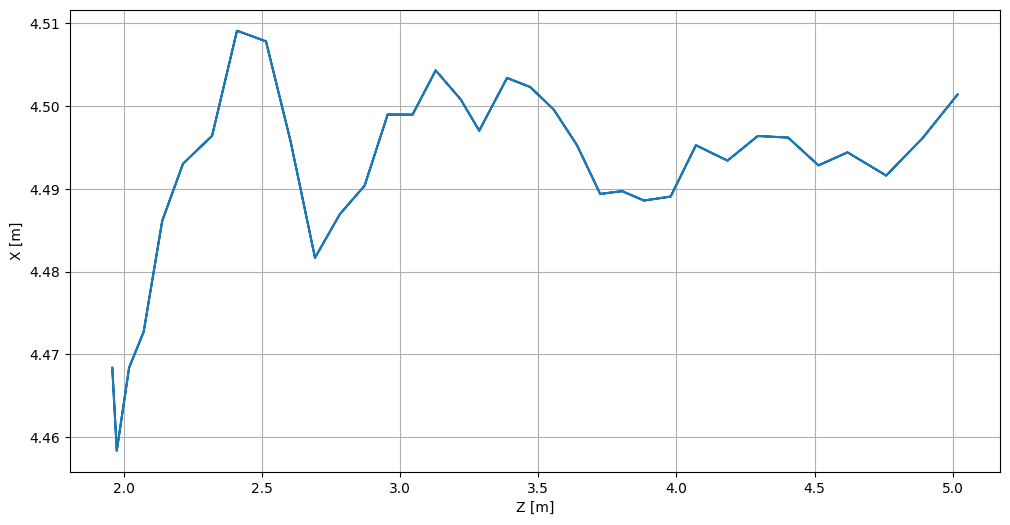

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(z_cranetip, x_cranetip)
plt.xlabel('Z [m]')
plt.ylabel('X [m]')
plt.grid(True)
plt.show()

The graphs are Realistic.
The crane tip moves stablely to the specific height. And it doesn't oscillate too much on horizontal direction.

### Calculate force acting on each cylinder
F1 * e1 = Mt * g * X

F2 * e2 = Mt * g * L2 * cos(th_2)

In [ ]:
F1 = Mt * g * x_cranetip / e_1 # N
F2 = Mt * g * L2 * np.cos(th_2) / e_2 # N
#display(F1 / 1000)
#display(F2 / 1000)

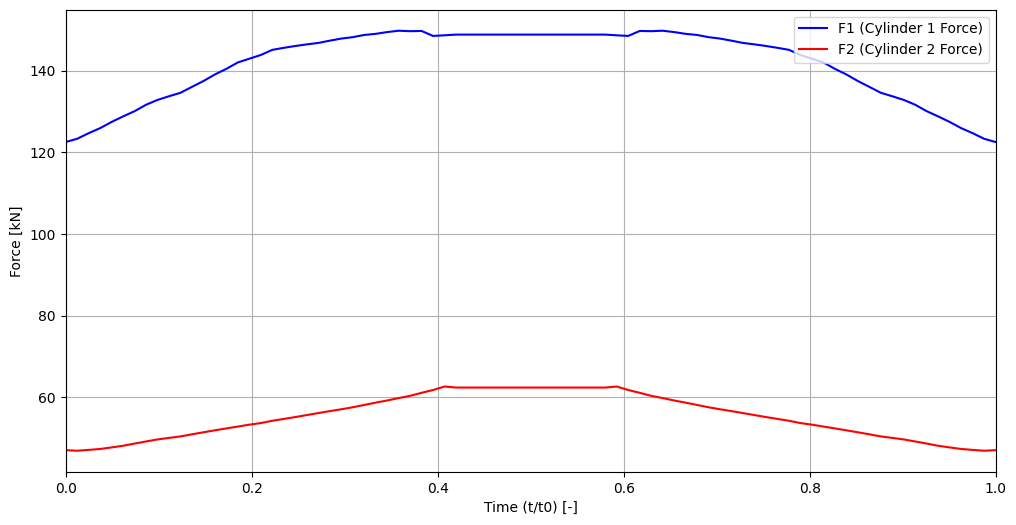

In [ ]:
plt.figure(figsize=(12, 6))

F1_kN = F1 / 1000
F2_kN = F2 / 1000

# Plotting both forces on a single axis
plt.plot(t / t0, F1_kN, color='blue', label='F1 (Cylinder 1 Force)')
plt.plot(t / t0, F2_kN, color='red', label='F2 (Cylinder 2 Force)')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Force [kN]')
#plt.title('Cylinder Forces F1 and F2 vs. Dimensionless Time')
plt.grid(True)
plt.xlim(0, 1)
plt.legend(loc='upper right')
plt.show()

##2 Dimension cylinders for the worst case

###
Calculate the minimum allowed cylinder diameters, D1 and D2, to be able to lift the maximum
load Mt,wc. Choose appropriate cylinders from one of the suppliers listed in the separate document Hydraulic Components.pdf. Remember to consider the cylinder efficiency and pressure
drops.


F1max = Mt,wc * g * (L1 * costh_1 + L1 * costh_2)

Assume the rod area is half of the piston area

F1max = (Psmax - 0.5 * Pr)* A1 * effC

In [ ]:
F1max = Mtmax * g * (L1 * math.cos(th_1_wc_cyl1) + L2 * math.cos(th_2_wc_cyl1)) / e_1_wc_cyl1
F2max = Mtmax * g * L2 * math.cos(th_2_wc_cyl2) / e_2_wc_cyl2
display(F1max / 1000) #kN
display(F2max / 1000)

322.8420343161414

222.16764705882352

In [ ]:
#Assumption Aa=x * Ap which means x = (piston Area - rod area) / piston area
x = 0.5
D1min = math.sqrt(F1max / (Psmax*1e5 - x * Plow) / effC * 4 / math.pi)
D2min = math.sqrt(F2max / (Psmax*1e5 - x * Plow) / effC * 4 / math.pi)
display(D1min * 1e3) #mm
display(D2min * 1e3) #mm

132.1999948532644

109.66721340223185

###Present calculated and chosen parameters.

**show the picked cylinder**
https://bosch-rexroth-embedded.partcommunity.com/3d-cad-models/h2-3x-hydraulic-cylinder-mill-type-cdh2-cgh2-csh2-bosch-rexroth?info=bosch_rexroth_mcd%2Findustrial_hydraulics%2Fcylinders%2Fmill_type_cylinders%2Fc_h2_asmtab.prj&cwid=0260

Brand:Bosch Rexroth

Type:H2-3X - Hydraulic cylinder Mill type CDH2

cylinder 1:
piston diameter: 140mm  rod diameter:100mm

cylinder 2:
piston diameter: 125mm rod diameter:80mm

In [ ]:
D1 = 0.14 #m
d1 = 0.1

D2 = 0.125 #m
d2 = 0.08

Ap1 = math.pi * D1**2 / 4
Ap2 = math.pi * D2**2 / 4

Aa1 = (D1**2 - d1**2) * math.pi / 4.0
Aa2 = (D2**2 - d2**2) * math.pi / 4.0

rr1 = Aa1/Ap1
rr2 = Aa2/Ap2
display(rr1)
display(rr2)

0.4897959183673469

0.5904

##3 Choose a suitable valve-controlled system for the crane (use the drive cycle)

### a Calculate and plot how the pressures (both chambers) in the two cylinders as well as the minimum required pump pressure vary during the drive cycle.

Because the force direction aligns with the negative piston velocity, so the piston side keeps the higher pressure side. Assume the pressure drops are $2\text{ MPa}$.

$$
P_p = \frac{\frac{F}{\eta_c} + P_r(A_p - A_r)}{A_p}
$$

$$P_r = P_{low}$$

In [ ]:
#cylinder1
Pp1 = np.linspace(Plow, Plow, len(th_1)) # Pa
Pr1 = np.linspace(Plow, Plow, len(th_1)) # Pa
Pp2 = np.linspace(Plow, Plow, len(th_1)) # Pa
Pr2 = np.linspace(Plow, Plow, len(th_1)) # Pa
Ptr = np.linspace(Plow, Plow, len(th_1)) # Pa minimum required pump pressure

for i in range(len(v_p01)):
  if(v_p01[i]>0): #motor
    Pp1[i] = (F1[i] / effC + Pr1[i] * rr1 * Ap1)/Ap1
  else:  #pump
    Pp1[i] = (F1[i] * effC + Pr1[i] * rr1 * Ap1)/Ap1

for i in range(len(v_p02)):
  if(v_p02[i]>0):
    Pp2[i] = (F2[i] / effC + Pr2[i] * rr2 * Ap2)/Ap2
  else:
    Pp2[i] = (F2[i] * effC + Pr2[i] * rr2 * Ap2)/Ap2

for i in range(len(th_1)):
    if(v_p01[i] >= 0 and v_p02[i] >= 0):
        Ptr[i] = max(Pp1[i], Pp2[i])
    elif(v_p01[i] >= 0 and v_p02[i] <= 0):
        Ptr[i] = Pp1[i]
    elif(v_p01[i] <= 0 and v_p02[i] >= 0):
        Ptr[i] = Pp2[i]
    else:
        Ptr[i] = Plow
Ptr += 2*1e6 # Add pressure drops
display(np.max(Ptr)*1e-6)

np.float64(12.62639158182166)

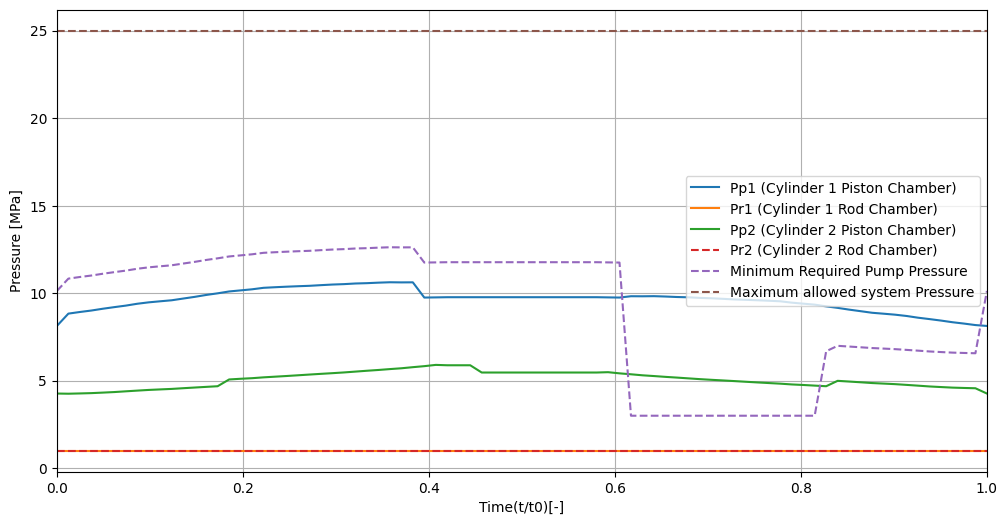

12.62639158182166


In [ ]:
plt.figure(figsize=(12, 6))

# Convert pressures to MPa for plotting
Pp1_MPa = Pp1 / 1e6
Pr1_MPa = Pr1 / 1e6
Pp2_MPa = Pp2 / 1e6
Pr2_MPa = Pr2 / 1e6
Ptr_MPa = Ptr / 1e6
Psmax_MPa = np.linspace(Psmax*1e5, Psmax*1e5, len(th_1)) / 1e6

plt.plot(t / t0, Pp1_MPa, label='Pp1 (Cylinder 1 Piston Chamber)')
plt.plot(t / t0, Pr1_MPa, label='Pr1 (Cylinder 1 Rod Chamber)')
plt.plot(t / t0, Pp2_MPa, label='Pp2 (Cylinder 2 Piston Chamber)')
plt.plot(t / t0, Pr2_MPa, label='Pr2 (Cylinder 2 Rod Chamber)', linestyle='--')
plt.plot(t / t0, Ptr_MPa, label='Minimum Required Pump Pressure', linestyle='--')
plt.plot(t / t0, Psmax_MPa, label='Maximum allowed system Pressure', linestyle='--')
plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Pressure [MPa]')
#plt.title('Cylinder Pressures and Minimum Pump Pressure vs. Dimensionless Time')
plt.grid(True)
plt.xlim(0, 1)
plt.legend()
plt.show()

print(np.max(Ptr_MPa))

###b Calculate and plot how the flow required from the pump by each cylinder varies during the drive
cycle
Include the total required pump flow and the maximum pump flow in the same graph

if piston velocity is positive, hydraulic fluid flows into the piston chamber, the flow equals to abs(v) * Ap
For the opposite side, the flow equals to
abs(v) * (Ap - Ar)

In [ ]:
vol_01 = np.linspace(0, 0, len(th_1))
vol_02 = np.linspace(0, 0, len(th_1))
vol_t = np.linspace(0, 0, len(th_1)) #total flow

for i in range(len(th_1)):
  if v_p01[i] > 0:
    vol_01[i] = v_p01[i]*vp0 * Ap1
  else:
    vol_01[i] = abs(v_p01[i])*vp0 * Ap1 * rr1
  if v_p02[i] > 0:
    vol_02[i] = v_p02[i]*vp0 * Ap2
  else:
    vol_02[i] = abs(v_p02[i])*vp0 * Ap2 * rr2
  vol_t[i] = vol_01[i] + vol_02[i]

maxq: 62.00511816295645


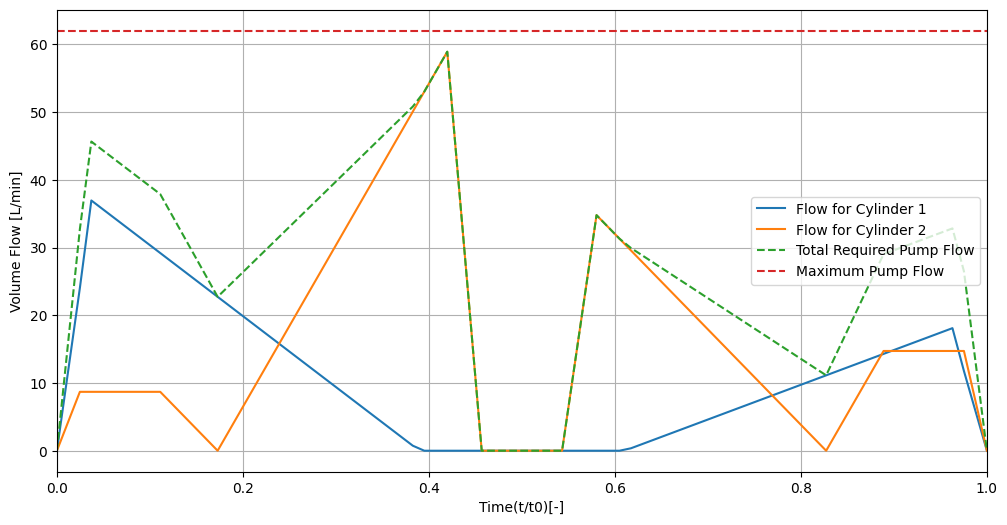

In [ ]:
plt.figure(figsize=(12, 6))

# Convert volumes from m^3 to Liters (1 m^3 = 1000 L)
vol_01_L = vol_01 * 1000 * 60
vol_02_L = vol_02 * 1000 * 60
vol_t_L = vol_t * 1000 * 60
#maximum pump flow

maxq = np.max(vol_t) * 1000 * 60 / qrwc
print("maxq:", maxq)
vol_max = np.linspace(maxq, maxq, len(th_1))

plt.plot(t / t0, vol_01_L, label='Flow for Cylinder 1')
plt.plot(t / t0, vol_02_L, label='Flow for Cylinder 2')
plt.plot(t / t0, vol_t_L, label='Total Required Pump Flow', linestyle='--')
plt.plot(t / t0, vol_max, label='Maximum Pump Flow', linestyle='--')

plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Volume Flow [L/min]') # Assuming v_p0 is in m/s, Ap in m^2, then vol is m^3/s
#plt.title('Cylinder and Total Pump Flow vs. Dimensionless Time')
plt.grid(True)
plt.xlim(0, 1)
#plt.ylim(0, 400)
plt.legend()
plt.show()

###c Choose a valve-controlled hydraulic system

compare the cost, driveability and efficiency

LS with variable displacement pump will be choosed for its flexibility to flow and pressure. It has a good driveability to adjust the flow and pressure. Though the initial cost is higher(variable displacement pump is expensive and the controlled valves are complicated), it runs efficiently. Const pressure system with variable pumps also fits for current situation, but when the flow through the cylinders tends to zero, the extra flow will flow through a pressure relief valve and the loss will be high.

###d Make a circuit diagram of your proposed hydraulic system for the crane

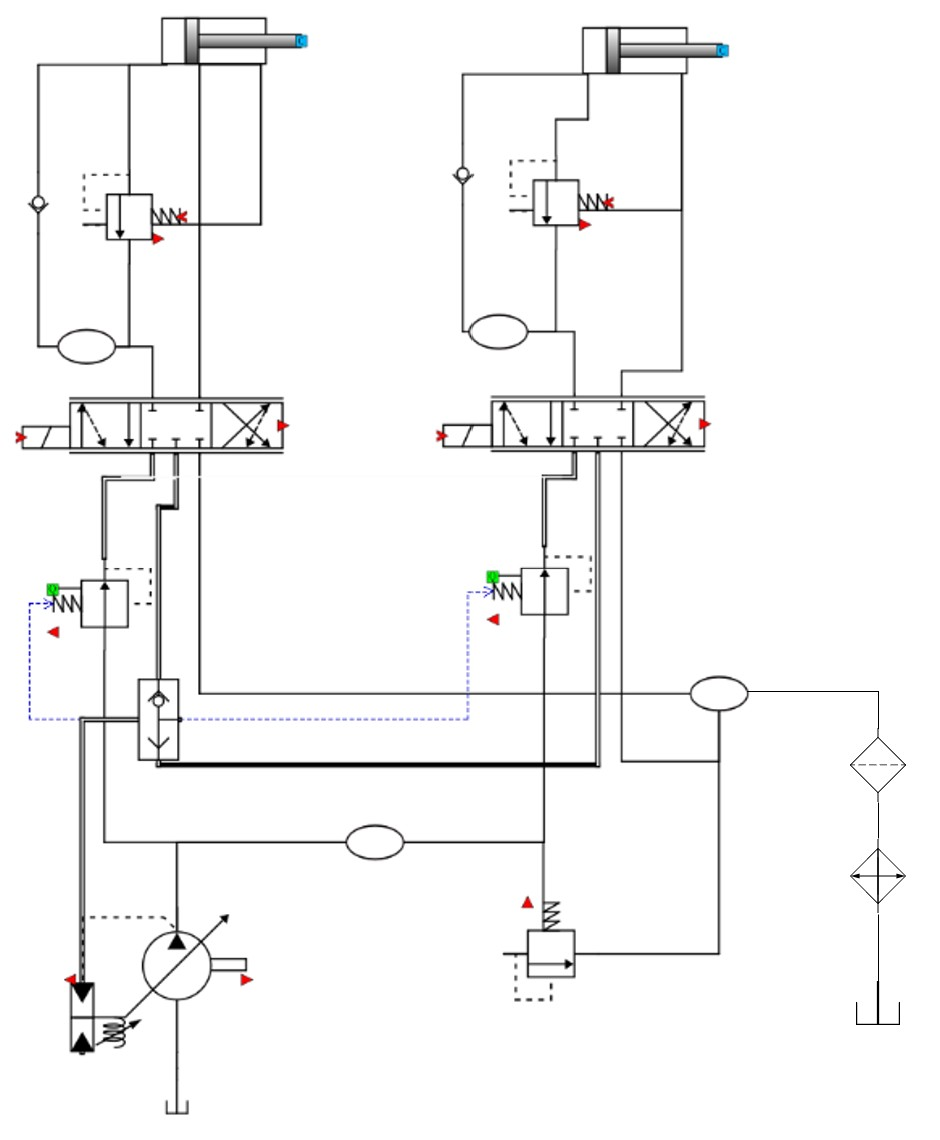

##4 Choose a pump

Bosch Rexroth A10VO 60 DFR/52

https://rexroth-parts.com/en/variable-displacement/a-a10v-o-60-dfr-52r-vuc61n00

Pump type	Swashplate axial piston, variable displacement

Maximum displacement	60 cm³/rev
Nominal pressure	250 bar
Maximum pressure	315 bar

DRF control
Pressure compensation (D)
Flow/displacement regulation (R)
Power limitation (F)

In [ ]:
# Pump parameters
Dp = 60e-6    # 70 cm3/rev to m3/rev
np_rev = 1800 / 60.0  # 1500 rpm to rev/s
safeDeltaP = 1.4 # 14bar

##5 Investigate how the system you have chosen performs during the drive cycle

a Present how the pump pressure in your system varies during the drive cycle

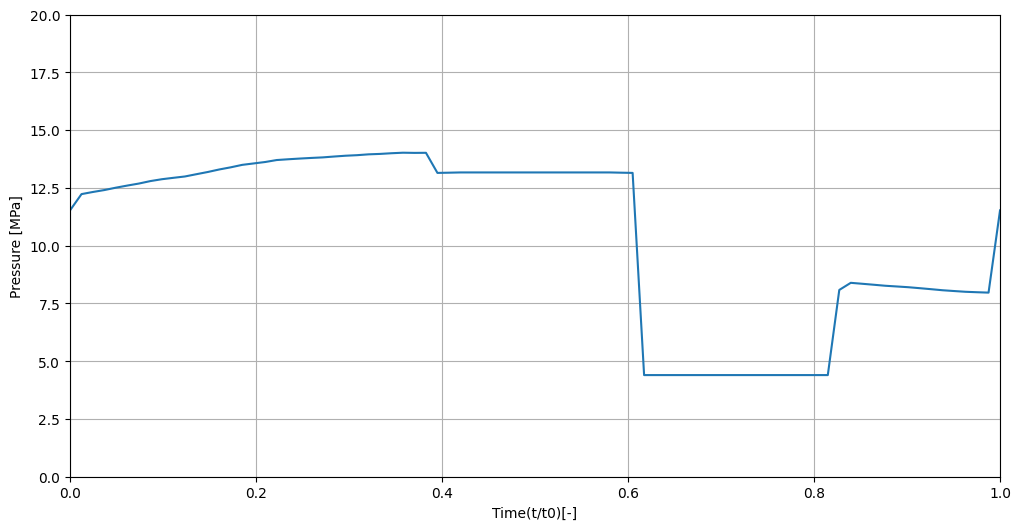

In [ ]:
for i in range(len(th_1)):
  Ptr_MPa[i] += 1.4
#print(Ptr_MPa)

plt.figure(figsize=(12, 6))
plt.plot(t / t0, Ptr_MPa)
plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Pressure [MPa]')
#plt.title('Cylinder Pressures and Minimum Pump Pressure vs. Dimensionless Time')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 20)
#plt.legend()
plt.show()

b Present how the pump flow in your system varies during the drive cycle

In [ ]:
n_p = np_rev
deltaP = np.linspace(0, 0, len(th_1))

inputPower = np.linspace(0, 0, len(th_1))
outputPower = np.linspace(0, 0, len(th_1))

for i in range(len(th_1)):
  deltaP[i] = (Ptr_MPa[i]-3.4) * 1e6

  if v_p01[i] > 0:
    outputPower[i] = v_p01[i]*vp0 * F1[i]
  else:
    inputPower[i] = abs(v_p01[i])*vp0 * F1[i]
  if v_p02[i] > 0:
    outputPower[i] += v_p02[i]*vp0 * F2[i]
  else:
    inputPower[i] += abs(v_p02[i])*vp0 * F2[i]

dispR = vol_t / (Dp * n_p) + cv*deltaP / (n_p * viscoEff)
etaVolp = 1 - cv * deltaP / dispR / (n_p * viscoEff)

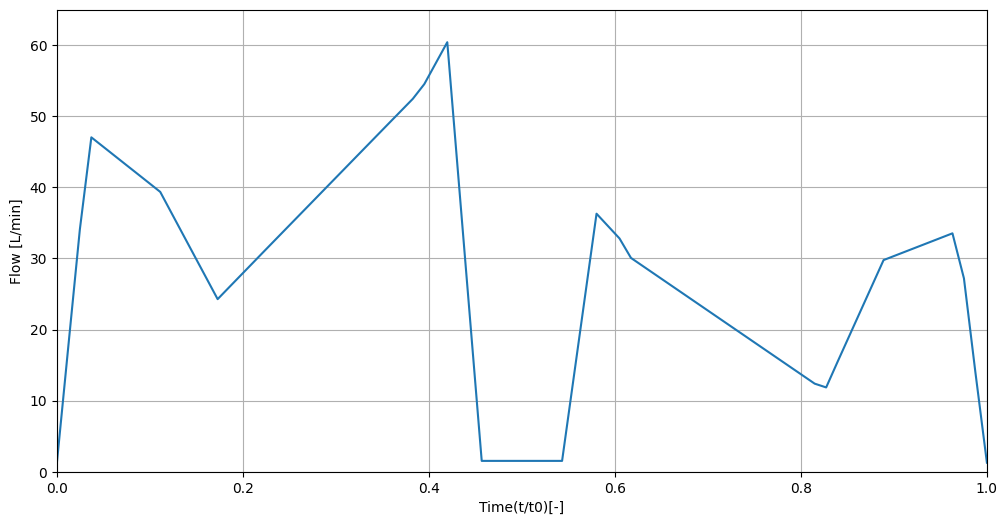

In [ ]:
plt.figure(figsize=(12, 6))
vol_t_L = vol_t * 1000 * 60
plt.plot(t / t0, dispR * Dp * np_rev* 1000 * 60)

plt.xlabel('Time(t/t0)[-]')
plt.ylabel('Flow [L/min]') # Assuming v_p0 is in m/s, Ap in m^2, then vol is m^3/s
#plt.title('Cylinder and Total Pump Flow vs. Dimensionless Time')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 65)
#plt.legend()
plt.show()

c. Plot how the pump displacement setting varies in your system during the drive cycle. In another
graph, plot how the pump efficiencies vary in your system during the drive cycle (3 curves:
volumetric, hydro-mechanical and total pump efficiency). Use the efficiency models on p. 9 in
the formula book.

In [ ]:
# Rename pump speed to n_p to avoid overriding numpy (np)

etaHmp = np.zeros_like(etaVolp)
for i in range(len(etaVolp)):
  etaHmp[i] = 1 / ( 1 + (kp + kv * n_p * viscoEff / deltaP[i]) * math.exp(ke * (1 - abs(etaVolp[i]))))

pumpPower = dispR * Dp * deltaP / etaHmp * n_p

effT = etaVolp * etaHmp

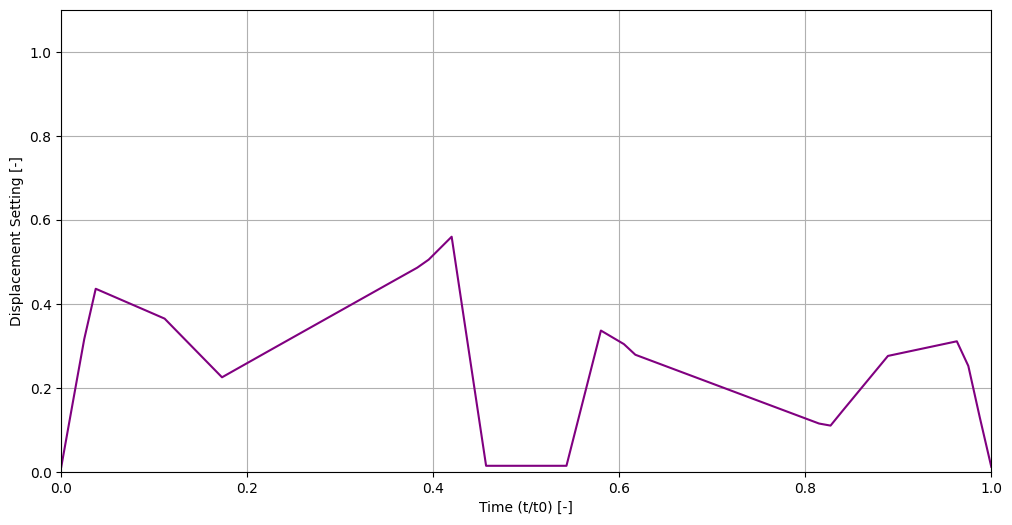

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t / t0, dispR, color='purple')
plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Displacement Setting [-]')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 1.1)
#plt.legend()
plt.show()

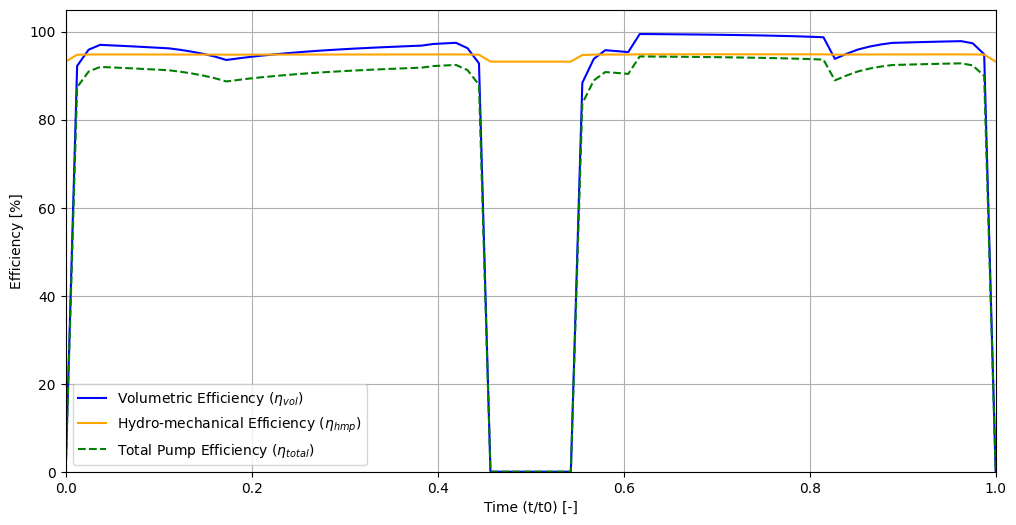

In [ ]:
eta_vol_pct = etaVolp * 100
eta_hm_pct = etaHmp * 100
eta_total_pct = effT * 100

plt.figure(figsize=(12, 6))
plt.plot(t / t0, eta_vol_pct, label='Volumetric Efficiency ($\\eta_{vol}$)', color='blue')
plt.plot(t / t0, eta_hm_pct, label='Hydro-mechanical Efficiency ($\\eta_{hmp}$)', color='orange')
plt.plot(t / t0, eta_total_pct, label='Total Pump Efficiency ($\\eta_{total}$)', color='green', linestyle='--')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Efficiency [%]')
#plt.title('Pump Efficiencies over the Drive Cycle')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 105)
plt.legend(loc='lower left')
plt.show()

d. Plot the input power to the pump and the output power from the cylinders during the drive cycle
in the same figure. How do you consider a “negative output power” component?


Negative output power is considered as input power of the system, converting the mechanical power into the hydraulic power.

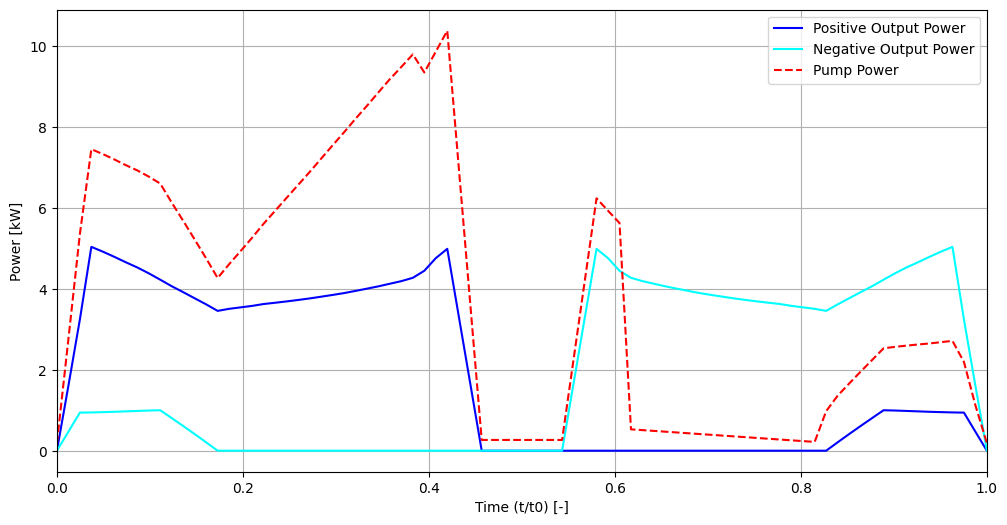

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t / t0, outputPower / 1000.0, label='Positive Output Power', color='blue')
plt.plot(t / t0, inputPower / 1000.0, label='Negative Output Power', color='cyan')
plt.plot(t / t0, pumpPower / 1000.0, label='Pump Power', color='red', linestyle='--')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Power [kW]')
plt.grid(True)
plt.xlim(0, 1)
plt.legend(loc='upper right')
plt.show()

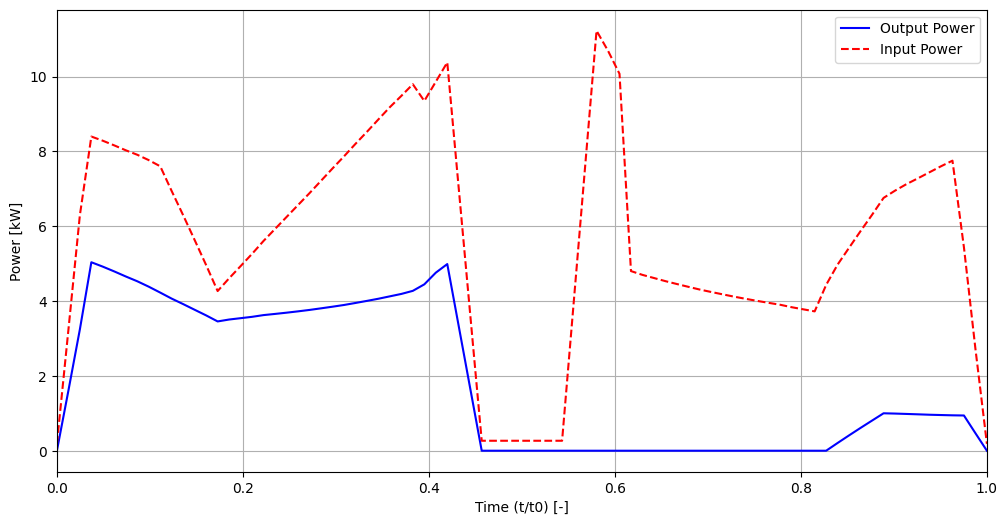

In [ ]:
# Calculate total input power (input power + pump power)
total_input_power = inputPower + pumpPower

plt.figure(figsize=(12, 6))
# Plot output power and total input power (converting to kW for readability)
plt.plot(t / t0, outputPower / 1000.0, label='Output Power', color='blue')
plt.plot(t / t0, (inputPower + pumpPower) / 1000.0, label='Input Power', color='red', linestyle='--')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Power [kW]')
#plt.title('Output Power vs. Total Input Power over the Drive Cycle')
plt.grid(True)
plt.xlim(0, 1)
plt.legend(loc='upper right')
plt.show()

e. Some general reflections: Are the losses high/low? Why? How would it change if you had used
another system type? Would you recommend a crane manufacturer to use your system?

Input power from the pump equals to deltap multiply q. If we use const pressure system, deltaP keeps high even if the required pressure is lower (t/t0 from 0.6 to 0.8);if const flow system is used, q will keep the losses higher under the condition of low flow.

##6 Dimension a cooler for your system

a.Some guiding questions to help you with the calculations: What is the net useful mechanical
work output for a full cycle (lifting and lowering of the mass)? No calculations are needed.
What does this imply regarding the relation between input power and losses?


It might be zero under an ideal conditions. Extra power(input power - output power = losses) from the pump converts to heat and dissipate through the throttling areas.

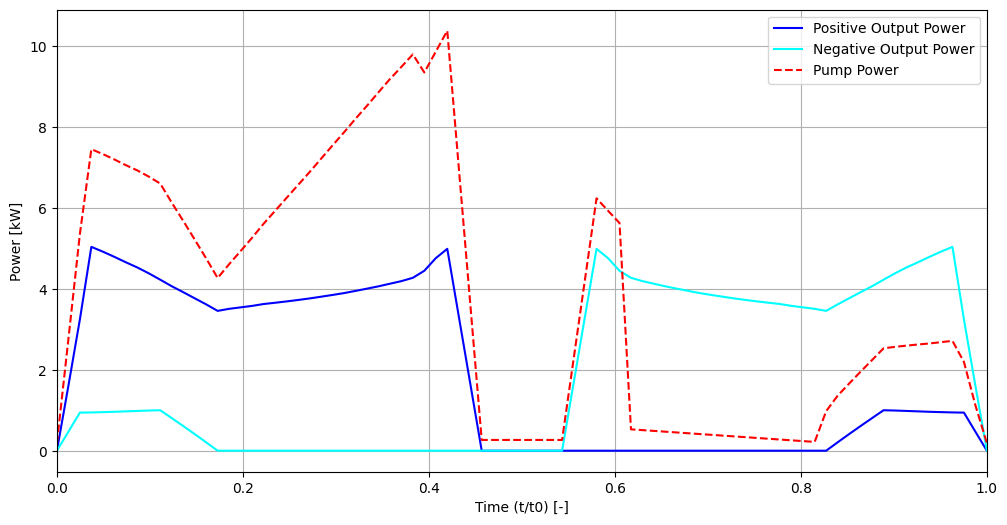

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t / t0, outputPower / 1000.0, label='Positive Output Power', color='blue')
plt.plot(t / t0, inputPower / 1000.0, label='Negative Output Power', color='cyan')
plt.plot(t / t0, pumpPower / 1000.0, label='Pump Power', color='red', linestyle='--')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Power [kW]')
plt.grid(True)
plt.xlim(0, 1)
plt.legend(loc='upper right')
plt.show()

b. Calculate the required average cooling power

In [ ]:
totalOutputPower = 0
totalInputPower = 0
deltaPower = pumpPower
totalLossPower = 0

for i in range(len(th_1)):
  if i == 0 : continue
  totalLossPower += (deltaPower[i]+deltaPower[i-1]) * (t[i] - t[i - 1]) / 2.0
#display(deltaPower)
avgCoolPower = (totalLossPower) / t0
print("Average cooling power:", avgCoolPower / 1000., "kW/s")

Average cooling power: 3.81767959338829 kW/s


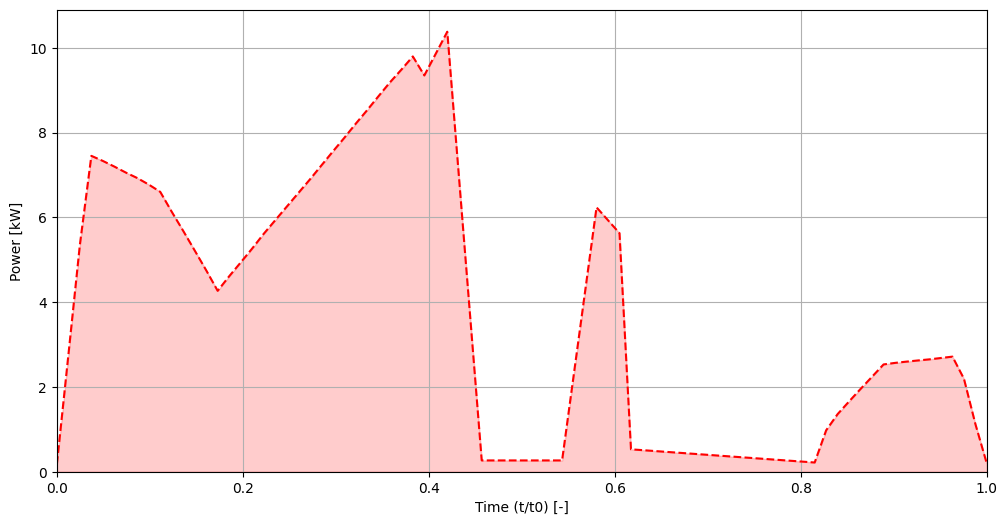

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(t / t0, pumpPower / 1000.0, label='Pump Power', color='red', linestyle='--')
plt.fill_between(t / t0, pumpPower / 1000.0, 0, color='red', alpha=0.2, label='Pump Power Area')

plt.xlabel('Time (t/t0) [-]')
plt.ylabel('Power [kW]')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(bottom=0)
#plt.legend(loc='upper right')
plt.show()